# Visualisations of the Tracked Regional European Events (OSTIA Observations) using `plotX`

This notebook plots the events tracked by [`02_id_track_events.ipynb`](02_id_track_events.ipynb), on the
anomalies written by [`01_preprocess_extremes.ipynb`](01_preprocess_extremes.ipynb). The figures follow
[`../gridded/03_visualise_events.ipynb`](../gridded/03_visualise_events.ipynb), drawn on a `PlateCarree` projection.
The basic tracking from `events_basic.zarr` appears in the third
movie. It holds only `ID_field`, so the figures that use centroids, event dates or areas need `events_merged.zarr`.

Compute: one compute node, with a local cluster of 32 single-threaded workers × 7 GB. The table at the end
reports the wall time and memory of each stage.

## Setup

In [1]:
from getpass import getuser
from pathlib import Path

import cartopy.crs as ccrs
import xarray as xr
from IPython.display import Video

import marEx
import marEx.helper as hpc

2026-10-19 01:28:33 - marEx - INFO - [PID:494134] - MarEx logging configured - Level: INFO, Mode: normal


In [2]:
scratch_dir = Path("/scratch") / getuser()[0] / getuser()  # Lustre scratch
out_dir = scratch_dir / "marEx" / "examples" / "regional"  # where notebooks 01 and 02 wrote their output
plot_dir = out_dir / "plots"

movie_period = slice("2020-01-01", "2022-05-31")
example_days = slice("2021-01-01", "2021-01-06")

# One compute node: 32 single-threaded workers x 7 GB = 224 GB. Movie frames render one per task without threads.
n_workers, threads_per_worker, memory_limit = 32, 1, "7GB"

In [3]:
plot_dir.mkdir(parents=True, exist_ok=True)

# memory_limit is passed explicitly because on an HPC node Dask sizes workers from the whole node's memory,
# not from the job's allocation, and without it the workers can claim more than the job was granted.
client = hpc.start_local_cluster(
    n_workers=n_workers,
    threads_per_worker=threads_per_worker,
    memory_limit=memory_limit,
    scratch_dir=scratch_dir / "marEx" / "dask",
)

# Records wall time, peak memory, spill and worker restarts for each `monitor.stage(...)` block below
monitor = hpc.ResourceMonitor(client)

2026-10-19 01:28:41 - marEx.helper.cluster - INFO - [PID:494134] - Starting local Dask cluster with 32 workers, 1 threads each


2026-10-19 01:28:41 - marEx.helper.dask_config - INFO - [PID:494134] - Configuring Dask for HPC environment


2026-10-19 01:28:41 - marEx.helper.dask_config - INFO - [PID:494134] - Dask temporary directory: /scratch/b/b382615/marEx/dask/tmpitssm3g2


2026-10-19 01:28:41 - marEx.helper.dask_config - INFO - [PID:494134] - Dask configuration completed


2026-10-19 01:28:41 - marEx.helper.cluster - INFO - [PID:494134] - System resources: 128 physical cores, 256 logical cores, 251.6GB total memory


...

2026-10-19 01:28:41 - marEx.helper.cluster - INFO - [PID:494134] - Starting Local cluster startup


2026-10-19 01:28:44 - marEx.helper.cluster - INFO - [PID:494134] - Completed Local cluster startup in 2.61s


Hostname: l10505
Forward Port: l10505:8787
Dashboard Link: localhost:8787/status
2026-10-19 01:28:44 - marEx.helper.cluster - INFO - [PID:494134] - Local cluster started successfully - Dashboard: http://127.0.0.1:8787/status


2026-10-19 01:28:44 - marEx.helper.cluster - INFO - [PID:494134] - After cluster startup - Memory Usage - RSS: 574.6MB, Virtual: 30749.9MB, Percent: 0.2%, Available: 244293.9MB


2026-10-19 01:28:44 - marEx.helper.resources - INFO - [PID:494134] - Cluster: 32 workers, 32 threads, memory_limit per worker [7.0] GB (224 GB total)


In [4]:
extremes_ds = xr.open_zarr(out_dir / "extremes_shifting_hobday.zarr", chunks={})
extreme_events_ds = xr.open_zarr(out_dir / "events_merged.zarr", chunks={})
ID_field = extreme_events_ds.ID_field
extreme_events_ds

<xarray.Dataset> Size: 31GB
Dimensions:       (ID: 3646, time: 9282, lat: 720, lon: 1060, component: 2,
                   sibling_ID: 14)
Coordinates:
  * ID            (ID) int32 15kB 1 2 3 4 5 6 ... 3641 3642 3643 3644 3645 3646
  * component     (component) int64 16B 0 1
  * lat           (lat) float32 3kB 30.02 30.08 30.12 ... 65.88 65.93 65.97
  * lon           (lon) float32 4kB -15.98 -15.93 -15.88 ... 36.88 36.92 36.97
  * time          (time) datetime64[ns] 74kB 1997-01-01T12:00:00 ... 2022-05-...
Dimensions without coordinates: sibling_ID
Data variables:
    ID_field      (time, lat, lon) int32 28GB dask.array<chunksize=(1, 720, 1060), meta=np.ndarray>
    area          (time, ID) float32 135MB dask.array<chunksize=(1, 3646), meta=np.ndarray>
    centroid      (component, time, ID) float32 271MB dask.array<chunksize=(1, 1, 3646), meta=np.ndarray>
    global_ID     (time, ID) int32 135MB dask.array<chunksize=(1, 3646), meta=np.ndarray>
    merge_ledger  (time, ID, sibling_ID) int32 2GB dask.array<chunksize=(1, 3646, 14), meta=np.ndarray>
    presence      (time, ID) bool 34MB dask.array<chunksize=(1, 3646), meta=np.ndarray>
    time_end      (ID) datetime64[ns] 29kB dask.array<chunksize=(3646,), meta=np.ndarray>
    time_start    (ID) datetime64[ns] 29kB dask.array<chunksize=(3646,), meta=np.ndarray>
Attributes: (12/14)
    N_events_final:              3646
    N_objects_filtered:          27344
    N_objects_prefiltered:       33669
    R_fill:                      16
    T_fill:                      4
    accepted_area_fraction:      0.9968276490480333
    ...                          ...
    area_threshold (cells):      600
    multi_parent_merges:         2562
    nn_partitioning:             1
    overlap_threshold:           0.25
    preprocessed_area_fraction:  0.7000620329473214
    total_merges:                6381

## 1. Movies using `plotX.animate`

`animate()` renders one frame per task and cannot use threads, which is why this notebook's cluster runs one thread
per worker. Each movie is written to `plot_dir`. The player shows the copy kept in the repository's
`media/` folder, which this notebook does not update. The third movie shows the same period from the basic tracking. See
[Animation](https://marex.readthedocs.io/en/latest/guide/visualisation.html#animations).

In [5]:
events_subset = extreme_events_ds.sel(time=movie_period)

with monitor.stage("Movie: event IDs"):
    config = marEx.PlotConfig(plot_IDs=True, projection=ccrs.PlateCarree())
    events_subset.ID_field.plotX.animate(
        config, plot_dir=plot_dir, file_name="movie_ID_field_regional", centroids=events_subset.centroid
    )
Video("../../media/movie_ID_field_regional.mp4", width=640, height=480, embed=False)

2026-10-19 01:29:10 - marEx - INFO - [PID:494435] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-19 01:29:10 - marEx - INFO - [PID:494414] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-19 01:29:10 - marEx - INFO - [PID:494419] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-19 01:29:10 - marEx - INFO - [PID:494476] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-19 01:29:10 - marEx - INFO - [PID:494459] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-19 01:29:10 - marEx - INFO - [PID:494426] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-19 01:29:10 - marEx - INFO - [PID:494451] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-19 01:29:10 - marEx - INFO - [PID:494402] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-19 01:29:10 - marEx - INFO - [PID:494447] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-19 01:29:10 - marEx - INFO - [PID:494487] - Mar

Movie: event IDs: 1.2 min, peak worker memory 22.8 GB of 224 GB (largest worker 0.8 of 7.0 GB), client 0.8 GB, spilled 0.0 GB, restarts 0


In [6]:
with monitor.stage("Movie: anomaly"):
    anomaly_subset = extremes_ds.dat_anomaly.sel(time=movie_period)
    anomaly_hot = anomaly_subset.where(anomaly_subset > 0, 0)  # warm anomalies only

    config = marEx.PlotConfig(var_units="Temperature Anomaly", cmap="inferno", cperc=[0, 98], projection=ccrs.PlateCarree())
    anomaly_hot.plotX.animate(
        config,
        plot_dir=plot_dir,
        file_name="movie_anomaly_regional",
        centroids=events_subset.centroid,
        object_ids=events_subset.ID_field,
    )
Video("../../media/movie_anomaly_regional.mp4", width=640, height=480, embed=False)

Movie: anomaly: 3.2 min, peak worker memory 29.1 GB of 224 GB (largest worker 1.1 of 7.0 GB), client 0.9 GB, spilled 0.0 GB, restarts 0


In [7]:
with monitor.stage("Movie: basic tracking IDs"):
    ID_field_basic_subset = xr.open_zarr(out_dir / "events_basic.zarr", chunks={}).ID_field.sel(time=movie_period)

    config = marEx.PlotConfig(plot_IDs=True, projection=ccrs.PlateCarree())
    ID_field_basic_subset.plotX.animate(config, plot_dir=plot_dir, file_name="movie_ID_field_basic_regional")
Video("../../media/movie_ID_field_basic_regional.mp4", width=640, height=480, embed=False)

Movie: basic tracking IDs: 0.8 min, peak worker memory 26.9 GB of 224 GB (largest worker 1.0 of 7.0 GB), client 0.9 GB, spilled 0.0 GB, restarts 0


## 2. Consecutive Days of Extreme Events

2026-10-19 01:33:57 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:33:57 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 0.22s


2026-10-19 01:33:57 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:33:58 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 0.24s


2026-10-19 01:33:58 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


...

2026-10-19 01:33:58 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 0.21s


2026-10-19 01:33:58 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:33:58 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 0.21s


2026-10-19 01:33:58 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:33:59 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 0.21s


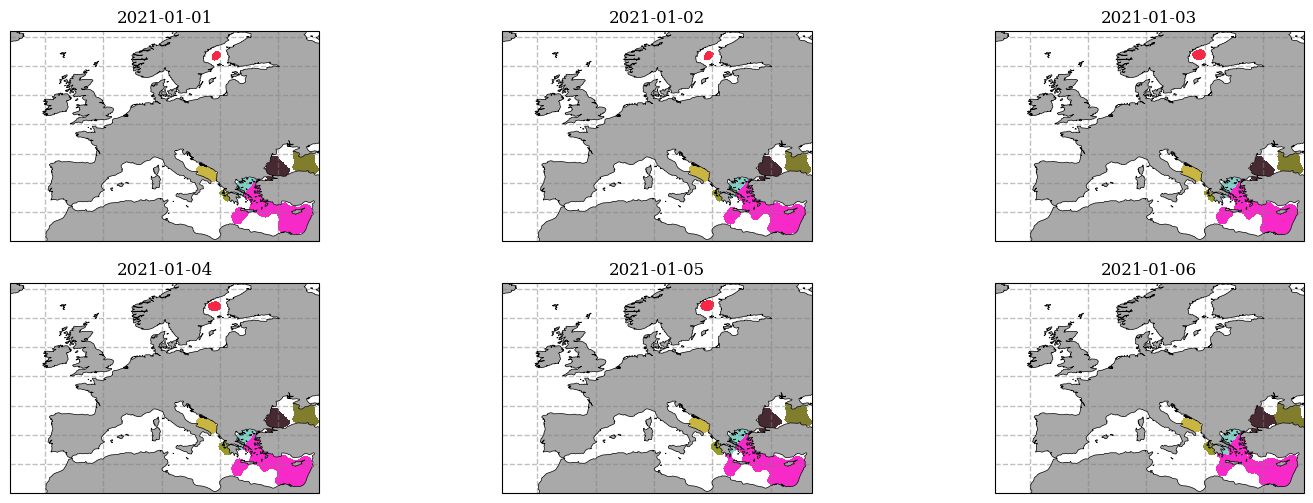

In [8]:
config = marEx.PlotConfig(plot_IDs=True, projection=ccrs.PlateCarree())
fig, ax = ID_field.sel(time=example_days).plotX.multi_plot(config, col="time", col_wrap=3);

## 3. Regional and Seasonal Extreme Event Frequency

2026-10-19 01:34:17 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:34:31 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 13.83s


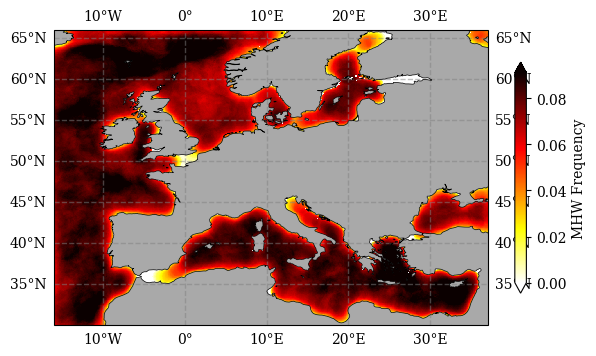

In [9]:
config = marEx.PlotConfig(var_units="MHW Frequency", cmap="hot_r", cperc=[0, 96], grid_labels=True, projection=ccrs.PlateCarree())

event_frequency = (ID_field > 0).mean("time")
fig, ax, im = event_frequency.plotX.single_plot(config)

2026-10-19 01:37:32 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:38:19 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 46.86s


2026-10-19 01:38:19 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:39:06 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 46.38s


2026-10-19 01:39:06 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:39:53 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 47.86s


2026-10-19 01:39:53 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:40:38 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 44.95s


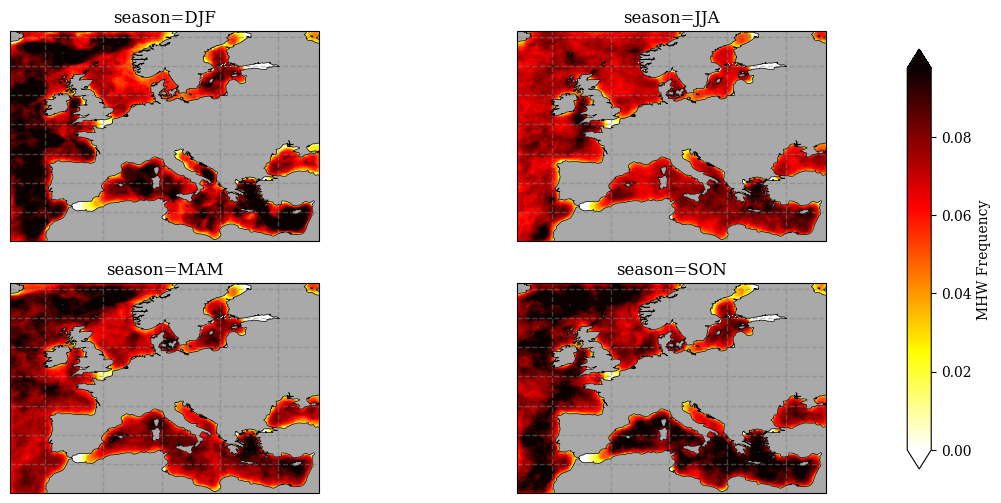

In [10]:
seasonal_frequency = (ID_field > 0).groupby("time.season").mean(dim="time")
fig, ax = seasonal_frequency.plotX.multi_plot(config, col="season", col_wrap=2);

## 4. The Longest Regional Events

In [11]:
events_duration = (extreme_events_ds.time_end - extreme_events_ds.time_start).dt.days + 1  # both ends inclusive
longest_events = events_duration.sortby(events_duration, ascending=False).ID

for ID in longest_events[:10].values:
    start = extreme_events_ds.time_start.sel(ID=ID).dt.strftime("%Y-%m-%d").values
    print(f"ID: {ID:<6}   Start Day: {start}  -->  Duration: {events_duration.sel(ID=ID).values:<4} days")

ID: 134      Start Day: 1997-09-19  -->  Duration: 196  days
ID: 136      Start Day: 1997-09-29  -->  Duration: 193  days
ID: 969      Start Day: 2002-11-19  -->  Duration: 190  days
ID: 974      Start Day: 2002-11-25  -->  Duration: 186  days
ID: 135      Start Day: 1997-09-22  -->  Duration: 182  days


ID: 3416     Start Day: 2020-09-05  -->  Duration: 177  days
ID: 1576     Start Day: 2006-10-10  -->  Duration: 170  days
ID: 1752     Start Day: 2007-10-08  -->  Duration: 162  days
ID: 145      Start Day: 1997-10-27  -->  Duration: 162  days
ID: 147      Start Day: 1997-11-08  -->  Duration: 156  days


2026-10-19 01:41:39 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:42:35 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 55.61s


2026-10-19 01:42:35 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:43:30 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 54.64s


2026-10-19 01:43:30 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


...

2026-10-19 01:48:00 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 54.01s


2026-10-19 01:48:00 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:48:54 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 53.86s


2026-10-19 01:48:54 - marEx.plotX.gridded - INFO - [PID:494134] - Starting Gridded plot rendering


2026-10-19 01:49:48 - marEx.plotX.gridded - INFO - [PID:494134] - Completed Gridded plot rendering in 53.78s


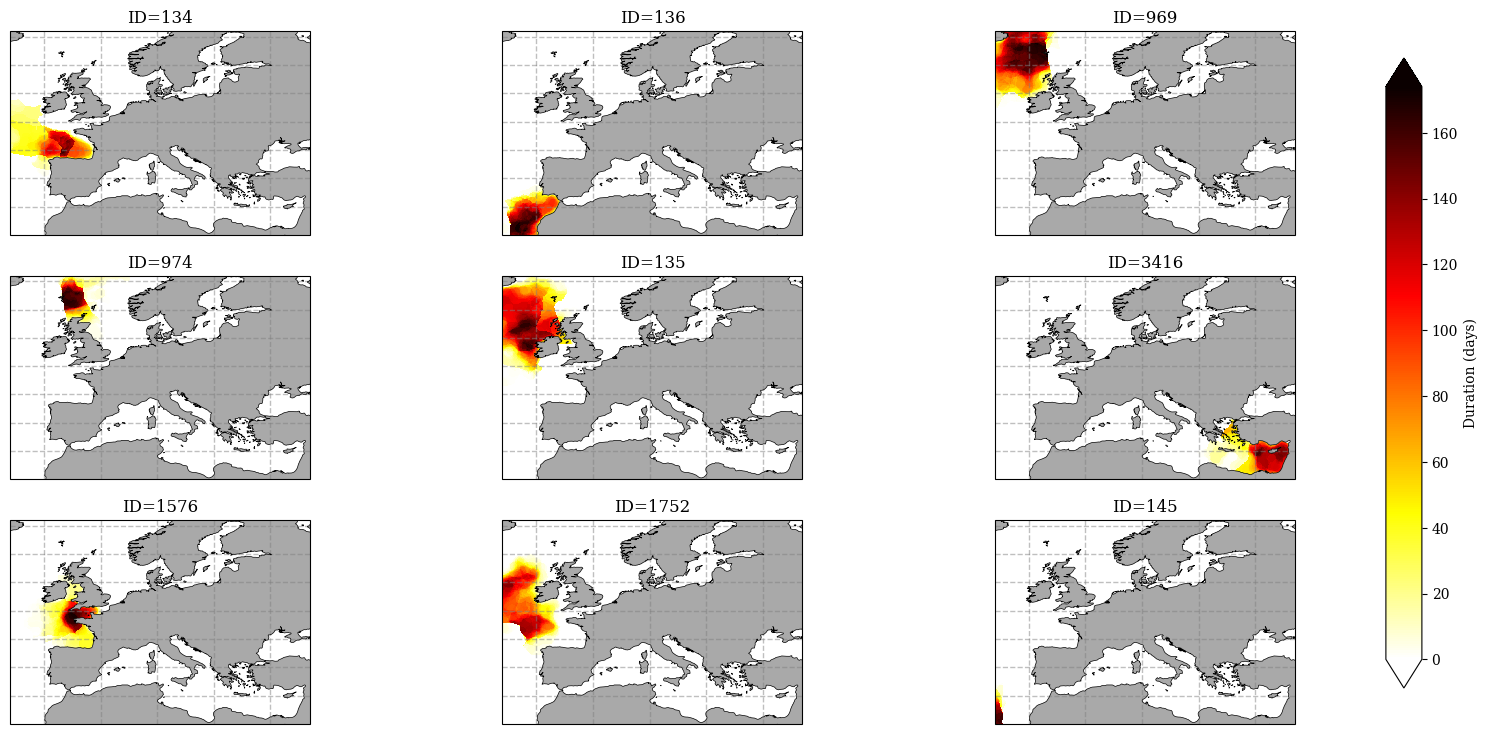

In [12]:
# Number of days each cell spent inside each of the nine longest events
long_events_local_duration = (ID_field == longest_events[:9].chunk({"ID": 1})).sum("time")

config = marEx.PlotConfig(var_units="Duration (days)", cmap="hot_r", cperc=[0, 100], projection=ccrs.PlateCarree())
fig, ax = long_events_local_duration.plotX.multi_plot(config, col="ID", col_wrap=3);

## 5. Maximum and Mean Event Area

In [13]:
areas_max, areas_mean = (extreme_events_ds.area.max(), extreme_events_ds.area.mean())
print(f"Maximum object area: {areas_max.values:.0f} km²")
print(f"Mean object area: {areas_mean.values:.0f} km²")

Maximum object area: 1271686 km²


Mean object area: 134461 km²


## Wall Time and Memory

Peak memory summed over workers, the largest single worker, and the client (this kernel), per stage.

In [14]:
monitor.summary()

,wall (min),peak worker memory (GB),peak per worker (GB),peak client memory (GB),peak spilled to disk (GB),worker restarts
stage,,,,,,
Movie: event IDs,1.19,22.78,0.79,0.81,0.0,0
Movie: anomaly,3.19,29.08,1.12,0.91,0.0,0
Movie: basic tracking IDs,0.83,26.89,1.04,0.93,0.0,0
total,5.21,29.08,1.12,0.93,0.0,0


In [15]:
client.close()